In [ ]:
!pip install -q pandas numpy matplotlib seaborn scipy statsmodels

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

urllib.request.urlretrieve(url, "bank_marketing.zip")

with zipfile.ZipFile("bank_marketing.zip", "r") as z:
    z.extractall("bank_data")

print("Dataset downloaded successfully!")
print(os.listdir("bank_data"))

Dataset downloaded successfully!
['bank.zip', 'bank-additional.zip']


In [ ]:
import os
import zipfile
import urllib.request

zip_path = "/content/bank.zip"

# Delete old ZIP file
if os.path.exists(zip_path):
    os.remove(zip_path)

# Download again
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

urllib.request.urlretrieve(url, zip_path)

print("ZIP size:", os.path.getsize(zip_path), "bytes")
print("ZIP valid:", zipfile.is_zipfile(zip_path))

ZIP size: 1023843 bytes
ZIP valid: True


In [ ]:
import os
import zipfile

if zipfile.is_zipfile("/content/bank.zip"):
    with zipfile.ZipFile("/content/bank.zip", "r") as z:
        z.extractall("/content/bank_data")
    print("Extract successful!")
else:
    print("ZIP download failed. Run Step 1 again.")

Extract successful!


In [ ]:
import os

for root, dirs, files in os.walk("/content/bank_data"):
    for file in files:
        if file == "bank-full.csv":
            print("CSV Path:", os.path.join(root, file))

In [ ]:
import os
import zipfile
import requests
import pandas as pd

os.makedirs("output", exist_ok=True)

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
zip_path = "output/bank_marketing.zip"

# Download dataset
response = requests.get(url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

print("Download successful!")

# Extract the outer ZIP
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("output/bank_data")

# Find bank-full.csv, including inside nested ZIP files
csv_path = None

for root, dirs, files_list in os.walk("output/bank_data"):
    for name in files_list:
        full_path = os.path.join(root, name)

        if name == "bank-full.csv":
            csv_path = full_path
            break

        if name == "bank.zip" and zipfile.is_zipfile(full_path):
            with zipfile.ZipFile(full_path, "r") as inner:
                if "bank-full.csv" in inner.namelist():
                    inner.extract("bank-full.csv", "output/bank_data")
                    csv_path = "output/bank_data/bank-full.csv"
                    break

    if csv_path:
        break

if csv_path is None:
    raise FileNotFoundError(
        "bank-full.csv not found. Please check the downloaded ZIP."
    )

# Load dataset
df = pd.read_csv(csv_path, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Download successful!
Dataset loaded successfully!
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
import numpy as np
import pandas as pd
import os

os.makedirs("output", exist_ok=True)

df.columns = df.columns.str.strip().str.lower()
df = df.replace("unknown", np.nan)
df = df.drop_duplicates().copy()

numeric_cols = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

df["y"] = df["y"].astype(str).str.lower().str.strip()
df = df[df["y"].isin(["yes", "no"])].copy()
df["subscribed"] = (df["y"] == "yes").astype(int)

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("unknown")

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 120],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

df["contacted_before"] = (df["pdays"] != 999).astype(int)

df["campaign_intensity"] = np.where(
    df["campaign"] > 3, "More than 3 contacts", "3 or fewer contacts"
)

df.to_csv("output/bank_marketing_cleaned.csv", index=False)

print("Cleaning completed")
print(df.shape)
display(df.head())

Cleaning completed
(45211, 21)


,age,job,marital,education,default,balance,housing,loan,contact,day,...,duration,campaign,pdays,previous,poutcome,y,subscribed,age_group,contacted_before,campaign_intensity
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,...,261,1,-1,0,unknown,no,0,56+,1,3 or fewer contacts
1,44,technician,single,secondary,no,29,yes,no,unknown,5,...,151,1,-1,0,unknown,no,0,36-45,1,3 or fewer contacts
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,...,76,1,-1,0,unknown,no,0,26-35,1,3 or fewer contacts
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,...,92,1,-1,0,unknown,no,0,46-55,1,3 or fewer contacts
4,33,unknown,single,unknown,no,1,no,no,unknown,5,...,198,1,-1,0,unknown,no,0,26-35,1,3 or fewer contacts


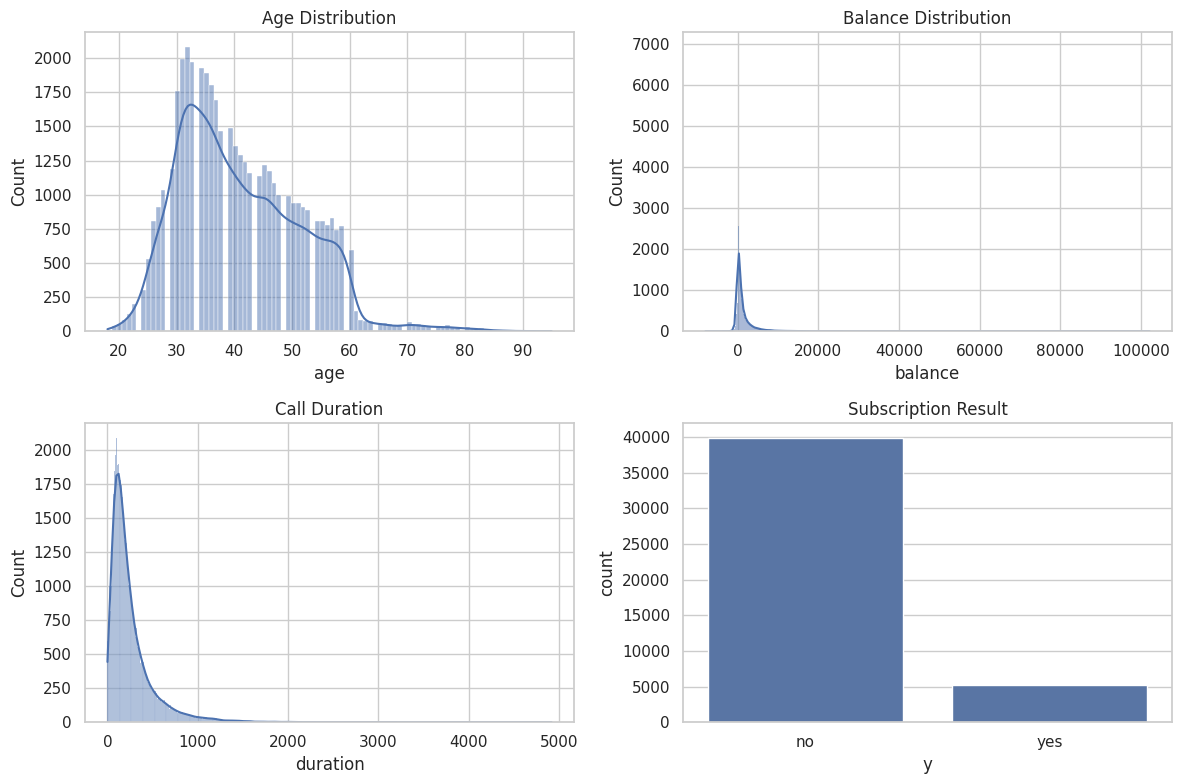

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x="age", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age Distribution")

sns.histplot(data=df, x="balance", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Balance Distribution")

sns.histplot(data=df, x="duration", kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Call Duration")

sns.countplot(data=df, x="y", ax=axes[1, 1])
axes[1, 1].set_title("Subscription Result")

plt.tight_layout()
plt.savefig("output/eda_charts.png")
plt.show()

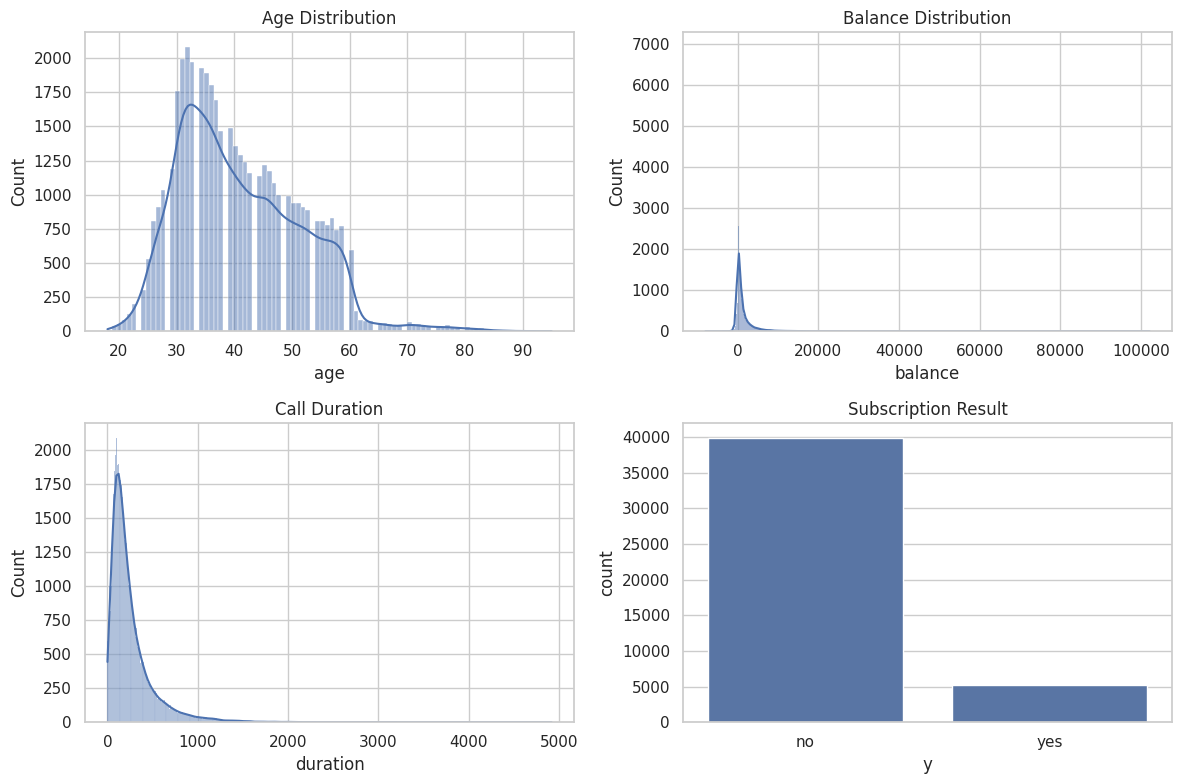

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x="age", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age Distribution")

sns.histplot(data=df, x="balance", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Balance Distribution")

sns.histplot(data=df, x="duration", kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Call Duration")

sns.countplot(data=df, x="y", ax=axes[1, 1])
axes[1, 1].set_title("Subscription Result")

plt.tight_layout()
plt.savefig("output/eda_charts.png")
plt.show()

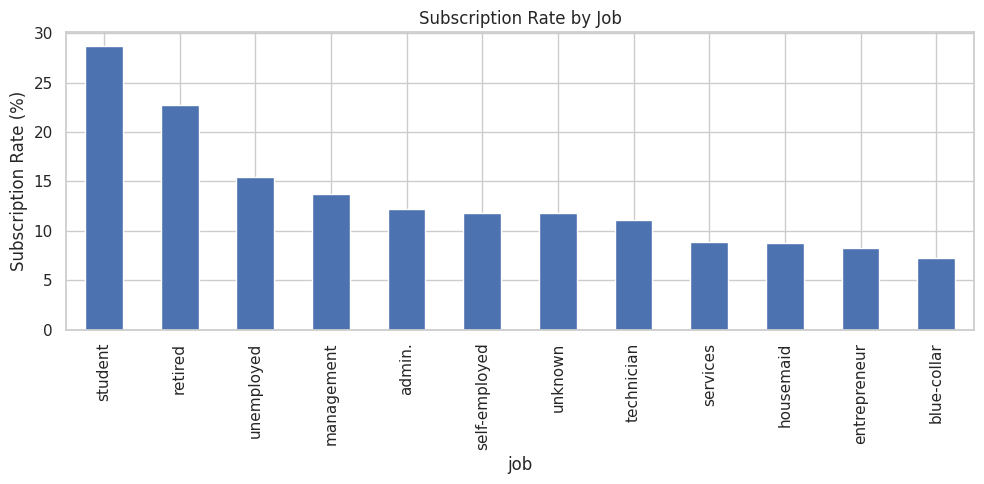

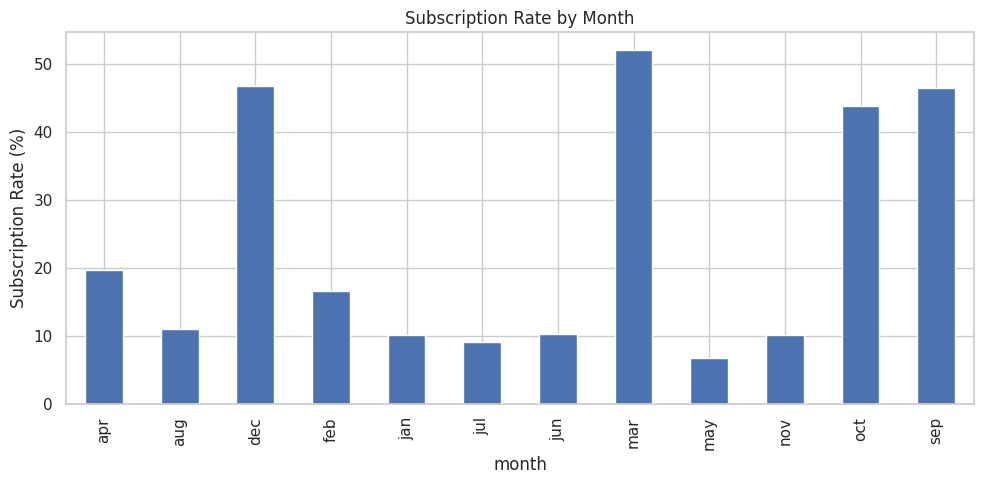

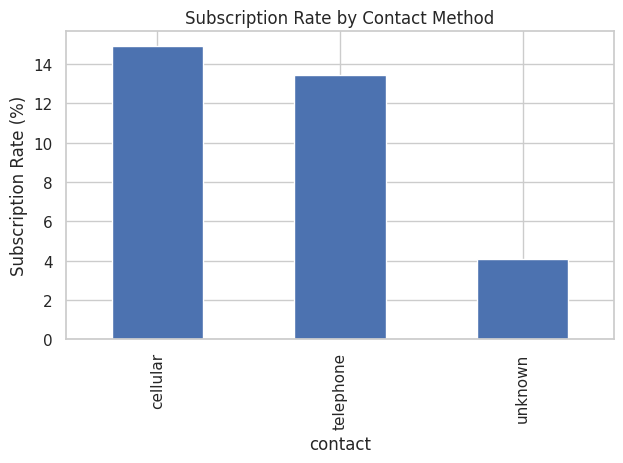

In [ ]:
job_rate = df.groupby("job")["subscribed"].mean().mul(100).sort_values(ascending=False)

job_rate.plot(kind="bar", figsize=(10, 5))
plt.title("Subscription Rate by Job")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("output/job_subscription.png")
plt.show()

month_rate = df.groupby("month")["subscribed"].mean().mul(100)

month_rate.plot(kind="bar", figsize=(10, 5))
plt.title("Subscription Rate by Month")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("output/month_subscription.png")
plt.show()

contact_rate = df.groupby("contact")["subscribed"].mean().mul(100)

contact_rate.plot(kind="bar")
plt.title("Subscription Rate by Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("output/contact_subscription.png")
plt.show()

In [ ]:
cols = ["age", "balance", "duration", "campaign"]

display(df[cols].describe())

for col in cols:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().iloc[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Skewness:", df[col].skew())

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outliers = df[
        (df[col] < q1 - 1.5 * iqr) |
        (df[col] > q3 + 1.5 * iqr)
    ]

    print(col, "Possible outliers:", len(outliers))

,age,balance,duration,campaign
count,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,258.163080,2.763841
std,10.618762,3044.765829,257.527812,3.098021
min,18.000000,-8019.000000,0.000000,1.000000
25%,33.000000,72.000000,103.000000,1.000000
50%,39.000000,448.000000,180.000000,2.000000
75%,48.000000,1428.000000,319.000000,3.000000
max,95.000000,102127.000000,4918.000000,63.000000



 age
Mean: 40.93621021432837
Median: 39.0
Mode: 32
Standard Deviation: 10.618762040975431
Variance: 112.75810728286069
Skewness: 0.6848179257252598

 balance
Mean: 1362.2720576850766
Median: 448.0
Mode: 0
Standard Deviation: 3044.7658291686002
Variance: 9270598.954472754
Skewness: 8.360308326166326

 duration
Mean: 258.1630797814691
Median: 180.0
Mode: 124
Standard Deviation: 257.52781226517095
Variance: 66320.57409008514
Skewness: 3.144318099423456

 campaign
Mean: 2.763840658246887
Median: 2.0
Mode: 1
Standard Deviation: 3.0980208832802205
Variance: 9.597733393240357
Skewness: 4.898650166179674
age Possible outliers: 487
balance Possible outliers: 4729
duration Possible outliers: 3235
campaign Possible outliers: 3064


In [ ]:
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

yes_balance = df[df["subscribed"] == 1]["balance"]
no_balance = df[df["subscribed"] == 0]["balance"]

t_stat, balance_p_value = stats.ttest_ind(
    yes_balance, no_balance, equal_var=False
)

print("Balance T-test p-value:", balance_p_value)

if balance_p_value < 0.05:
    print("Significant difference")
else:
    print("No significant difference")

table = pd.crosstab(df["contact"], df["y"])

chi2, chi_p_value, dof, expected = stats.chi2_contingency(table)

print("Contact Chi-square p-value:", chi_p_value)

ab = df[df["contact"].isin(["cellular", "telephone"])]

cell = ab[ab["contact"] == "cellular"]["subscribed"]
phone = ab[ab["contact"] == "telephone"]["subscribed"]

if len(cell) > 0 and len(phone) > 0:
    count = np.array([cell.sum(), phone.sum()])
    total = np.array([len(cell), len(phone)])

    z_stat, ab_p_value = proportions_ztest(count, total)

    print("Cellular subscription rate:", cell.mean() * 100)
    print("Telephone subscription rate:", phone.mean() * 100)
    print("A/B test p-value:", ab_p_value)
else:
    ab_p_value = np.nan
    print("A/B test skipped")

Balance T-test p-value: 4.3837327771001536e-23
Significant difference
Contact Chi-square p-value: 1.251738325340638e-225
Cellular subscription rate: 14.918900460986853
Telephone subscription rate: 13.420509291121817
A/B test p-value: 0.029962756506797035


In [ ]:
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

yes_balance = df[df["subscribed"] == 1]["balance"]
no_balance = df[df["subscribed"] == 0]["balance"]

t_stat, balance_p_value = stats.ttest_ind(
    yes_balance, no_balance, equal_var=False
)

print("Balance T-test p-value:", balance_p_value)

if balance_p_value < 0.05:
    print("Significant difference")
else:
    print("No significant difference")

table = pd.crosstab(df["contact"], df["y"])

chi2, chi_p_value, dof, expected = stats.chi2_contingency(table)

print("Contact Chi-square p-value:", chi_p_value)

ab = df[df["contact"].isin(["cellular", "telephone"])]

cell = ab[ab["contact"] == "cellular"]["subscribed"]
phone = ab[ab["contact"] == "telephone"]["subscribed"]

if len(cell) > 0 and len(phone) > 0:
    count = np.array([cell.sum(), phone.sum()])
    total = np.array([len(cell), len(phone)])

    z_stat, ab_p_value = proportions_ztest(count, total)

    print("Cellular subscription rate:", cell.mean() * 100)
    print("Telephone subscription rate:", phone.mean() * 100)
    print("A/B test p-value:", ab_p_value)
else:
    ab_p_value = np.nan
    print("A/B test skipped")

Balance T-test p-value: 4.3837327771001536e-23
Significant difference
Contact Chi-square p-value: 1.251738325340638e-225
Cellular subscription rate: 14.918900460986853
Telephone subscription rate: 13.420509291121817
A/B test p-value: 0.029962756506797035


Subscription Probability: 0.11698480458295547
Subscription Percentage: 11.698480458295547
Normality test p-value: 1.680636368527385e-79


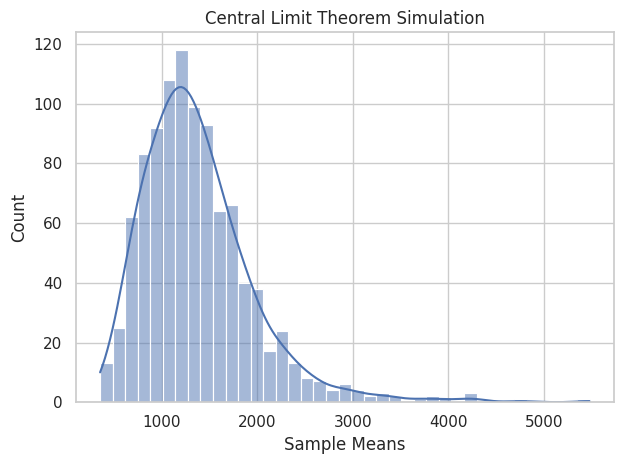

Original mean: 1362.2720576850766
Sample means average: 1375.9501666666667


In [ ]:
print("Subscription Probability:", df["subscribed"].mean())
print("Subscription Percentage:", df["subscribed"].mean() * 100)

sample = df["balance"].dropna()

if len(sample) > 5000:
    sample = sample.sample(5000, random_state=42)

normal_stat, normal_p = stats.shapiro(sample)

print("Normality test p-value:", normal_p)

values = df["balance"].dropna().to_numpy()
rng = np.random.default_rng(42)

sample_size = min(30, len(values))

sample_means = [
    rng.choice(values, size=sample_size, replace=True).mean()
    for _ in range(1000)
]

sns.histplot(sample_means, kde=True)
plt.title("Central Limit Theorem Simulation")
plt.xlabel("Sample Means")
plt.tight_layout()
plt.savefig("output/clt_chart.png")
plt.show()

print("Original mean:", values.mean())
print("Sample means average:", np.mean(sample_means))

Subscription Probability: 0.11698480458295547
Subscription Percentage: 11.698480458295547
Normality test p-value: 1.680636368527385e-79


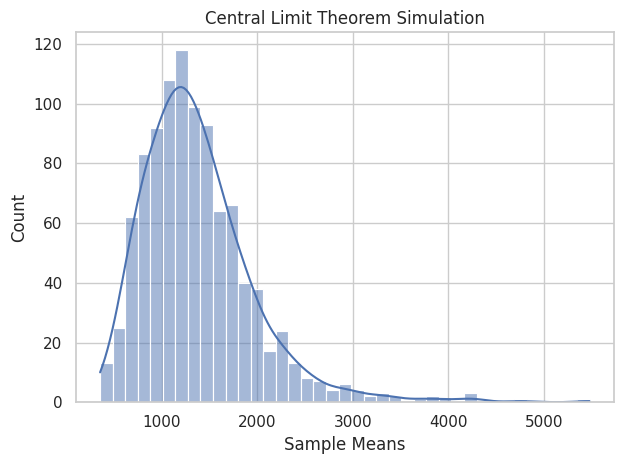

Original mean: 1362.2720576850766
Sample means average: 1375.9501666666667


In [ ]:
print("Subscription Probability:", df["subscribed"].mean())
print("Subscription Percentage:", df["subscribed"].mean() * 100)

sample = df["balance"].dropna()

if len(sample) > 5000:
    sample = sample.sample(5000, random_state=42)

normal_stat, normal_p = stats.shapiro(sample)

print("Normality test p-value:", normal_p)

values = df["balance"].dropna().to_numpy()
rng = np.random.default_rng(42)

sample_size = min(30, len(values))

sample_means = [
    rng.choice(values, size=sample_size, replace=True).mean()
    for _ in range(1000)
]

sns.histplot(sample_means, kde=True)
plt.title("Central Limit Theorem Simulation")
plt.xlabel("Sample Means")
plt.tight_layout()
plt.savefig("output/clt_chart.png")
plt.show()

print("Original mean:", values.mean())
print("Sample means average:", np.mean(sample_means))

In [ ]:
bayesian_results = []

for outcome, group in df.groupby("poutcome", dropna=False):
    success = group["subscribed"].sum()
    failure = len(group) - success

    alpha = 1 + success
    beta = 1 + failure

    bayesian_results.append({
        "Previous Outcome": outcome,
        "Customers": len(group),
        "Subscribers": int(success),
        "Observed Rate": success / len(group),
        "Posterior Probability": alpha / (alpha + beta)
    })

bayes_df = pd.DataFrame(bayesian_results)

display(
    bayes_df.sort_values(
        "Posterior Probability", ascending=False
    )
)

bayes_df.to_csv("output/bayesian_results.csv", index=False)

,Previous Outcome,Customers,Subscribers,Observed Rate,Posterior Probability
2,success,1511,978,0.647253,0.647059
1,other,1840,307,0.166848,0.167210
0,failure,4901,618,0.126097,0.126249
3,unknown,36959,3386,0.091615,0.091637


In [ ]:
import sqlite3

conn = sqlite3.connect("output/bank_marketing.db")

df.to_sql(
    "bank_marketing",
    conn,
    if_exists="replace",
    index=False
)

print("Database created successfully")

Database created successfully


In [ ]:
queries = {
    "Subscription by Job": """
        SELECT job,
               COUNT(*) AS customers,
               SUM(subscribed) AS subscribers,
               ROUND(AVG(subscribed)*100, 2) AS success_rate
        FROM bank_marketing
        GROUP BY job
        ORDER BY success_rate DESC
    """,

    "Top 5 Months": """
        SELECT month, SUM(subscribed) AS subscribers
        FROM bank_marketing
        GROUP BY month
        ORDER BY subscribers DESC
        LIMIT 5
    """,

    "Campaign More Than 3 Contacts": """
        SELECT COUNT(*) AS customers,
               SUM(subscribed) AS subscribers,
               ROUND(AVG(subscribed)*100, 2) AS success_rate
        FROM bank_marketing
        WHERE campaign > 3
    """,

    "Average Duration": """
        SELECT y, ROUND(AVG(duration), 2) AS avg_duration
        FROM bank_marketing
        GROUP BY y
    """,

    "Subscription by Education": """
        SELECT education,
               COUNT(*) AS customers,
               ROUND(AVG(subscribed)*100, 2) AS success_rate
        FROM bank_marketing
        GROUP BY education
        ORDER BY success_rate DESC
    """
}

sql_text = ""

for title, query in queries.items():
    print("\n", title)
    display(pd.read_sql_query(query, conn))
    sql_text += f"-- {title}\n{query};\n\n"

with open("output/bank_marketing_queries.sql", "w") as f:
    f.write(sql_text)

conn.close()

print("SQL queries saved")


 Subscription by Job


,job,customers,subscribers,success_rate
0,student,938,269,28.68
1,retired,2264,516,22.79
2,unemployed,1303,202,15.50
3,management,9458,1301,13.76
4,admin.,5171,631,12.20
5,self-employed,1579,187,11.84
6,unknown,288,34,11.81
7,technician,7597,840,11.06
8,services,4154,369,8.88
9,housemaid,1240,109,8.79



 Top 5 Months


,month,subscribers
0,may,925
1,aug,688
2,jul,627
3,apr,577
4,jun,546



 Campaign More Than 3 Contacts


,customers,subscribers,success_rate
0,9641,709,7.35



 Average Duration


,y,avg_duration
0,no,221.18
1,yes,537.29



 Subscription by Education


,education,customers,success_rate
0,tertiary,13301,15.01
1,unknown,1857,13.57
2,secondary,23202,10.56
3,primary,6851,8.63


SQL queries saved


In [ ]:
total = len(df)
subscribers = int(df["subscribed"].sum())
rate = df["subscribed"].mean() * 100

report = f"""
BANK MARKETING PROJECT REPORT

1. Objective
To analyze customer data and understand term-deposit subscriptions.

2. Dataset
Total customers: {total}
Total subscribers: {subscribers}
Non-subscribers: {total - subscribers}
Subscription rate: {rate:.2f}%

3. Descriptive Statistics
Average age: {df['age'].mean():.2f}
Median age: {df['age'].median():.2f}
Average balance: {df['balance'].mean():.2f}
Average call duration: {df['duration'].mean():.2f}
Balance skewness: {df['balance'].skew():.2f}

4. Findings
Highest observed subscription-rate job: {job_rate.idxmax()}
Highest observed subscription-rate month: {month_rate.idxmax()}

5. Hypothesis Testing
Balance t-test p-value: {balance_p_value:.6g}
Contact chi-square p-value: {chi_p_value:.6g}
A/B test p-value: {ab_p_value:.6g}

6. CLT and Bayesian Analysis
The CLT simulation shows the distribution of repeated sample means.
The Bayesian section uses a Beta(1,1) prior to smooth subscription rates.

7. SQL Analysis
SQL queries compare subscription rates by job and education,
top months by subscriber count, campaign intensity, and duration.

8. Conclusion
The analysis identifies patterns associated with subscription.
Statistical association does not prove causation. Call duration is
recorded during the call and may not be available before contact.
"""

with open("output/bank_marketing_report.txt", "w") as f:
    f.write(report)

print(report)


BANK MARKETING PROJECT REPORT

1. Objective
To analyze customer data and understand term-deposit subscriptions.

2. Dataset
Total customers: 45211
Total subscribers: 5289
Non-subscribers: 39922
Subscription rate: 11.70%

3. Descriptive Statistics
Average age: 40.94
Median age: 39.00
Average balance: 1362.27
Average call duration: 258.16
Balance skewness: 8.36

4. Findings
Highest observed subscription-rate job: student
Highest observed subscription-rate month: mar

5. Hypothesis Testing
Balance t-test p-value: 4.38373e-23
Contact chi-square p-value: 1.25174e-225
A/B test p-value: 0.0299628

6. CLT and Bayesian Analysis
The CLT simulation shows the distribution of repeated sample means.
The Bayesian section uses a Beta(1,1) prior to smooth subscription rates.

7. SQL Analysis
SQL queries compare subscription rates by job and education,
top months by subscriber count, campaign intensity, and duration.

8. Conclusion
The analysis identifies patterns associated with subscription.
Statisti

In [ ]:
import os
import zipfile
from google.colab import files

with zipfile.ZipFile(
    "Bank_Marketing_Project.zip", "w", zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, file_list in os.walk("output"):
        for file in file_list:
            path = os.path.join(root, file)
            z.write(path, arcname=path)

files.download("Bank_Marketing_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>